Este notebook documenta un proceso de clasificación multiclase utilizando máquinas de vectores de soporte (SVM) para detectar diferentes tipos de fraude y transacciones legítimas en un conjunto de datos financieros.

El proceso incluye la carga de datos, la creación de una variable objetivo multiclase, la división y escalado de los datos, el entrenamiento y evaluación de modelos SVM utilizando estrategias One-vs-Rest (OvR) y One-vs-One (OvO), y la visualización de los resultados, incluyendo matrices de confusión y fronteras de decisión.

### 📥 1. Carga de librerías y datos

Se cargan las librerías necesarias para el análisis y modelado, incluyendo `pandas` para manejo de datos, `numpy` para operaciones numéricas, `sklearn` para modelado y evaluación, y `matplotlib`/`seaborn` para visualización. Posteriormente, se carga el conjunto de datos desde un archivo CSV.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# Cargar el dataset desde el archivo
df = pd.read_csv("/content/df_CC_SI_ED_Balanceado_Con_Outliers.csv")

# Visualizar primeras filas
df.head()


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,fraud_category_5_classes
0,6.547739,1.098351,-0.296479,-0.309,0.734987,0,1,0,0,0,Fraude - Retiro (Cash Out) - Alto Monto
1,-0.076041,-0.244310,-0.296479,-0.309,-0.326398,0,0,0,0,1,Fraude - Transferencia - Alto Monto
2,-0.307868,-0.239389,-0.245129,-0.309,-0.326398,0,0,0,1,0,Legitima
3,-0.064738,-0.242019,-0.296479,-0.309,-0.277779,0,1,0,0,0,Fraude - Retiro (Cash Out) - Alto Monto
4,-0.277450,-0.285136,-0.296479,-0.309,-0.326398,0,0,0,0,1,Fraude - Transferencia - Bajo Monto


### 📊 2. Crear la variable objetivo multiclase

Se define una función `asignar_clase` para crear una variable objetivo multiclase (`clase_objetivo`) basada en el tipo de transacción (`type_TRANSFER`, `type_CASH_OUT`) y si el monto (`amount`) es mayor o menor que la mediana de todos los montos. Esto permite categorizar las transacciones en cinco clases distintas: "Fraude - Transferencia - Bajo Monto", "Fraude - Transferencia - Alto Monto", "Fraude - Retiro (Cash Out) - Bajo Monto", "Fraude - Retiro (Cash Out) - Alto Monto" y "Legítima". Se muestra el conteo de instancias por cada clase para verificar el balance del dataset.

In [2]:
# Calcular la mediana del monto
mediana_monto = df["amount"].median()

def asignar_clase(row):
    if row["type_TRANSFER"] == 1:
        return "Fraude - Transferencia - Bajo Monto" if row["amount"] < mediana_monto else "Fraude - Transferencia - Alto Monto"
    elif row["type_CASH_OUT"] == 1:
        return "Fraude - Retiro (Cash Out) - Bajo Monto" if row["amount"] < mediana_monto else "Fraude - Retiro (Cash Out) - Alto Monto"
    else:
        return "Legítima"

df["clase_objetivo"] = df.apply(asignar_clase, axis=1)
df["clase_objetivo"].value_counts()


,count
clase_objetivo,
Fraude - Retiro (Cash Out) - Alto Monto,1806
Fraude - Transferencia - Bajo Monto,1444
Fraude - Transferencia - Alto Monto,1056
Fraude - Retiro (Cash Out) - Bajo Monto,1006
Legítima,688


### 🎯 3. Definir variables predictoras y objetivo

Se seleccionan las características numéricas originales (`amount`, `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) como variables predictoras (`X`) y la variable `clase_objetivo` como la variable objetivo (`y`) para el modelo de clasificación.

In [3]:
# Usamos las columnas numéricas originales
X = df[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]]
y = df["clase_objetivo"]


### ✂️ 4. División de datos y escalado

El conjunto de datos se divide en conjuntos de entrenamiento y prueba utilizando `train_test_split`. Se reserva el 30% de los datos para prueba (`test_size=0.3`) y se utiliza `stratify=y` para asegurar que la distribución de clases sea similar en ambos conjuntos. Se aplica `StandardScaler` para normalizar las características (`X_train_scaled`, `X_test_scaled`), un paso importante para los modelos SVM basados en distancias.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    stratify=y,
                                                    random_state=42)

# Normalización (CC = Sí)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### 🧠 5. Entrenamiento del modelo One-vs-Rest

Se entrena un clasificador SVM con un kernel RBF (`SVC(kernel="rbf", C=1)`) utilizando la estrategia One-vs-Rest (`OneVsRestClassifier`). En esta estrategia, se entrena un clasificador binario independiente para cada clase, donde cada clasificador distingue una clase específica de todas las demás. Se evalúa el rendimiento del modelo en el conjunto de prueba utilizando métricas como precisión, recall, f1-score y accuracy, presentadas en un reporte de clasificación.

In [5]:
modelo_ovr = OneVsRestClassifier(SVC(kernel="rbf", C=1))
modelo_ovr.fit(X_train_scaled, y_train)

y_pred_ovr = modelo_ovr.predict(X_test_scaled)
print("Accuracy (OvR):", accuracy_score(y_test, y_pred_ovr))
print(classification_report(y_test, y_pred_ovr))


Accuracy (OvR): 0.7533333333333333
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.85      0.93      0.89       542
Fraude - Retiro (Cash Out) - Bajo Monto       0.76      0.41      0.54       302
    Fraude - Transferencia - Alto Monto       0.99      0.73      0.84       317
    Fraude - Transferencia - Bajo Monto       0.58      1.00      0.74       433
                               Legítima       0.92      0.32      0.47       206

                               accuracy                           0.75      1800
                              macro avg       0.82      0.68      0.69      1800
                           weighted avg       0.80      0.75      0.74      1800



### 🧠 6. Entrenamiento del modelo One-vs-One

Se entrena otro clasificador SVM con kernel RBF (`SVC(kernel="rbf", C=1, probability=True)`) utilizando la estrategia One-vs-One (`OneVsOneClassifier`). En esta estrategia, se entrena un clasificador binario para cada par de clases posibles. La predicción final se basa en un voto mayoritario entre los clasificadores binarios. Se habilita `probability=True` para posibles usos posteriores (aunque no se utiliza directamente en la evaluación mostrada). Se evalúa el rendimiento del modelo de manera similar a la estrategia OvR.

In [6]:
modelo_ovo = OneVsOneClassifier(SVC(kernel="rbf", C=1, probability=True)) # Added probability=True
modelo_ovo.fit(X_train_scaled, y_train)

y_pred_ovo = modelo_ovo.predict(X_test_scaled)
print("Accuracy (OvO):", accuracy_score(y_test, y_pred_ovo))
print(classification_report(y_test, y_pred_ovo))

Accuracy (OvO): 0.7644444444444445
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.94      0.88      0.91       542
Fraude - Retiro (Cash Out) - Bajo Monto       0.78      0.64      0.70       302
    Fraude - Transferencia - Alto Monto       0.94      0.67      0.78       317
    Fraude - Transferencia - Bajo Monto       0.57      1.00      0.73       433
                               Legítima       0.95      0.30      0.45       206

                               accuracy                           0.76      1800
                              macro avg       0.84      0.70      0.71      1800
                           weighted avg       0.83      0.76      0.76      1800



### 📉 7. Matriz de confusión

Se define una función `plot_confusion` para visualizar la matriz de confusión de los modelos. La matriz de confusión muestra el número de predicciones correctas e incorrectas para cada clase, permitiendo evaluar el rendimiento del modelo en la identificación de cada tipo de transacción. Se generan matrices de confusión para ambos modelos (OvR y OvO) en el conjunto de prueba.

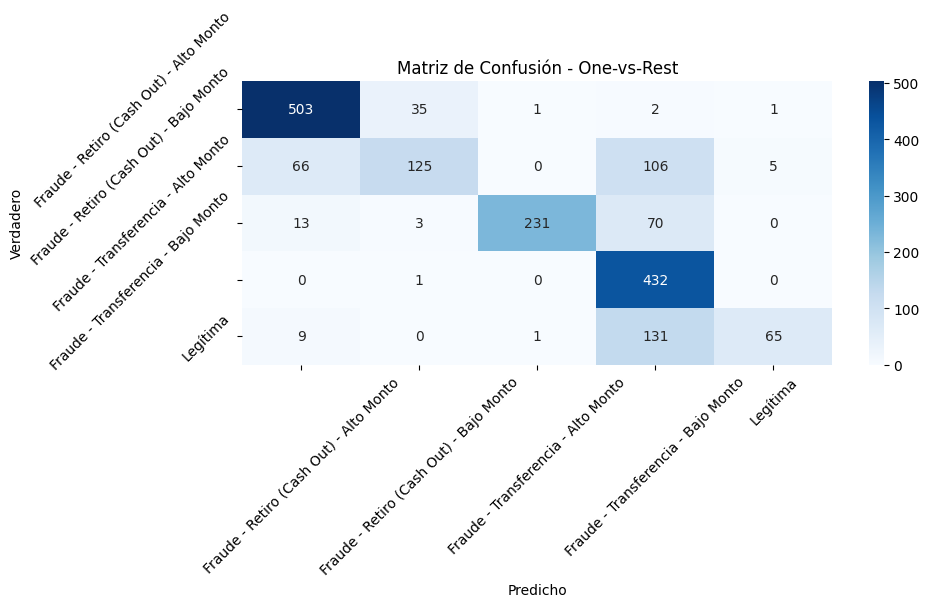

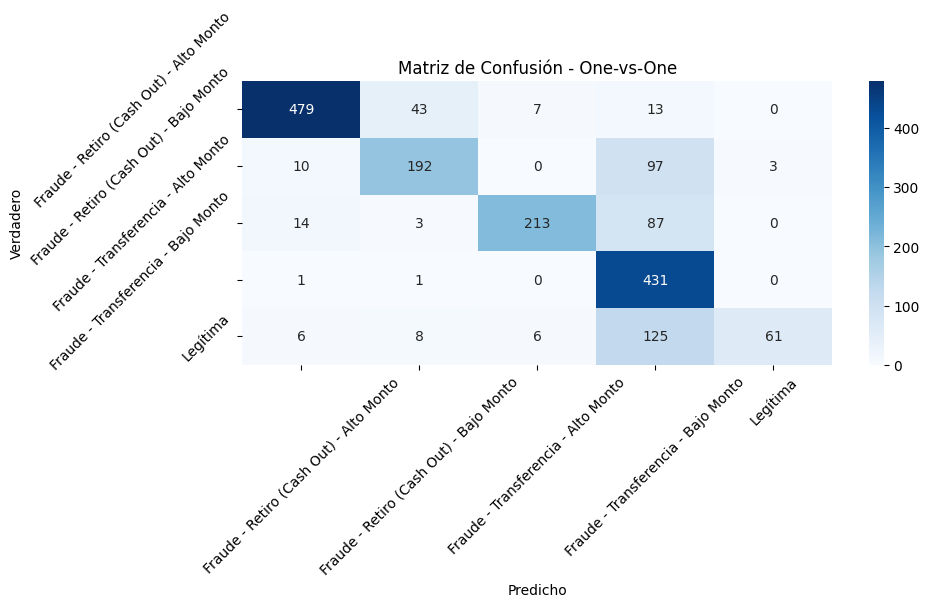

In [7]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=np.unique(y))
    plt.figure(figsize=(10,6))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=np.unique(y),
                yticklabels=np.unique(y),
                cmap="Blues")
    plt.title(f"Matriz de Confusión - {title}")
    plt.ylabel("Verdadero")
    plt.xlabel("Predicho")
    plt.xticks(rotation=45)
    plt.yticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_confusion(y_test, y_pred_ovr, "One-vs-Rest")
plot_confusion(y_test, y_pred_ovo, "One-vs-One")


### 📊 8. Visualización de Fronteras de Decisión (2D)

Esta sección se dedica a visualizar las fronteras de decisión aprendidas por un modelo SVM en un espacio de dos dimensiones. Se seleccionan dos características (`amount`, `oldbalanceOrg`) y se entrena un modelo `SVC` con kernel lineal para cada clase en un enfoque One-vs-Rest. Se genera una malla de puntos y se predice la clase para cada punto de la malla para visualizar la región de decisión de cada clasificador binario OvR. Los puntos de datos se colorean según si pertenecen o no a la clase que está siendo distinguida.

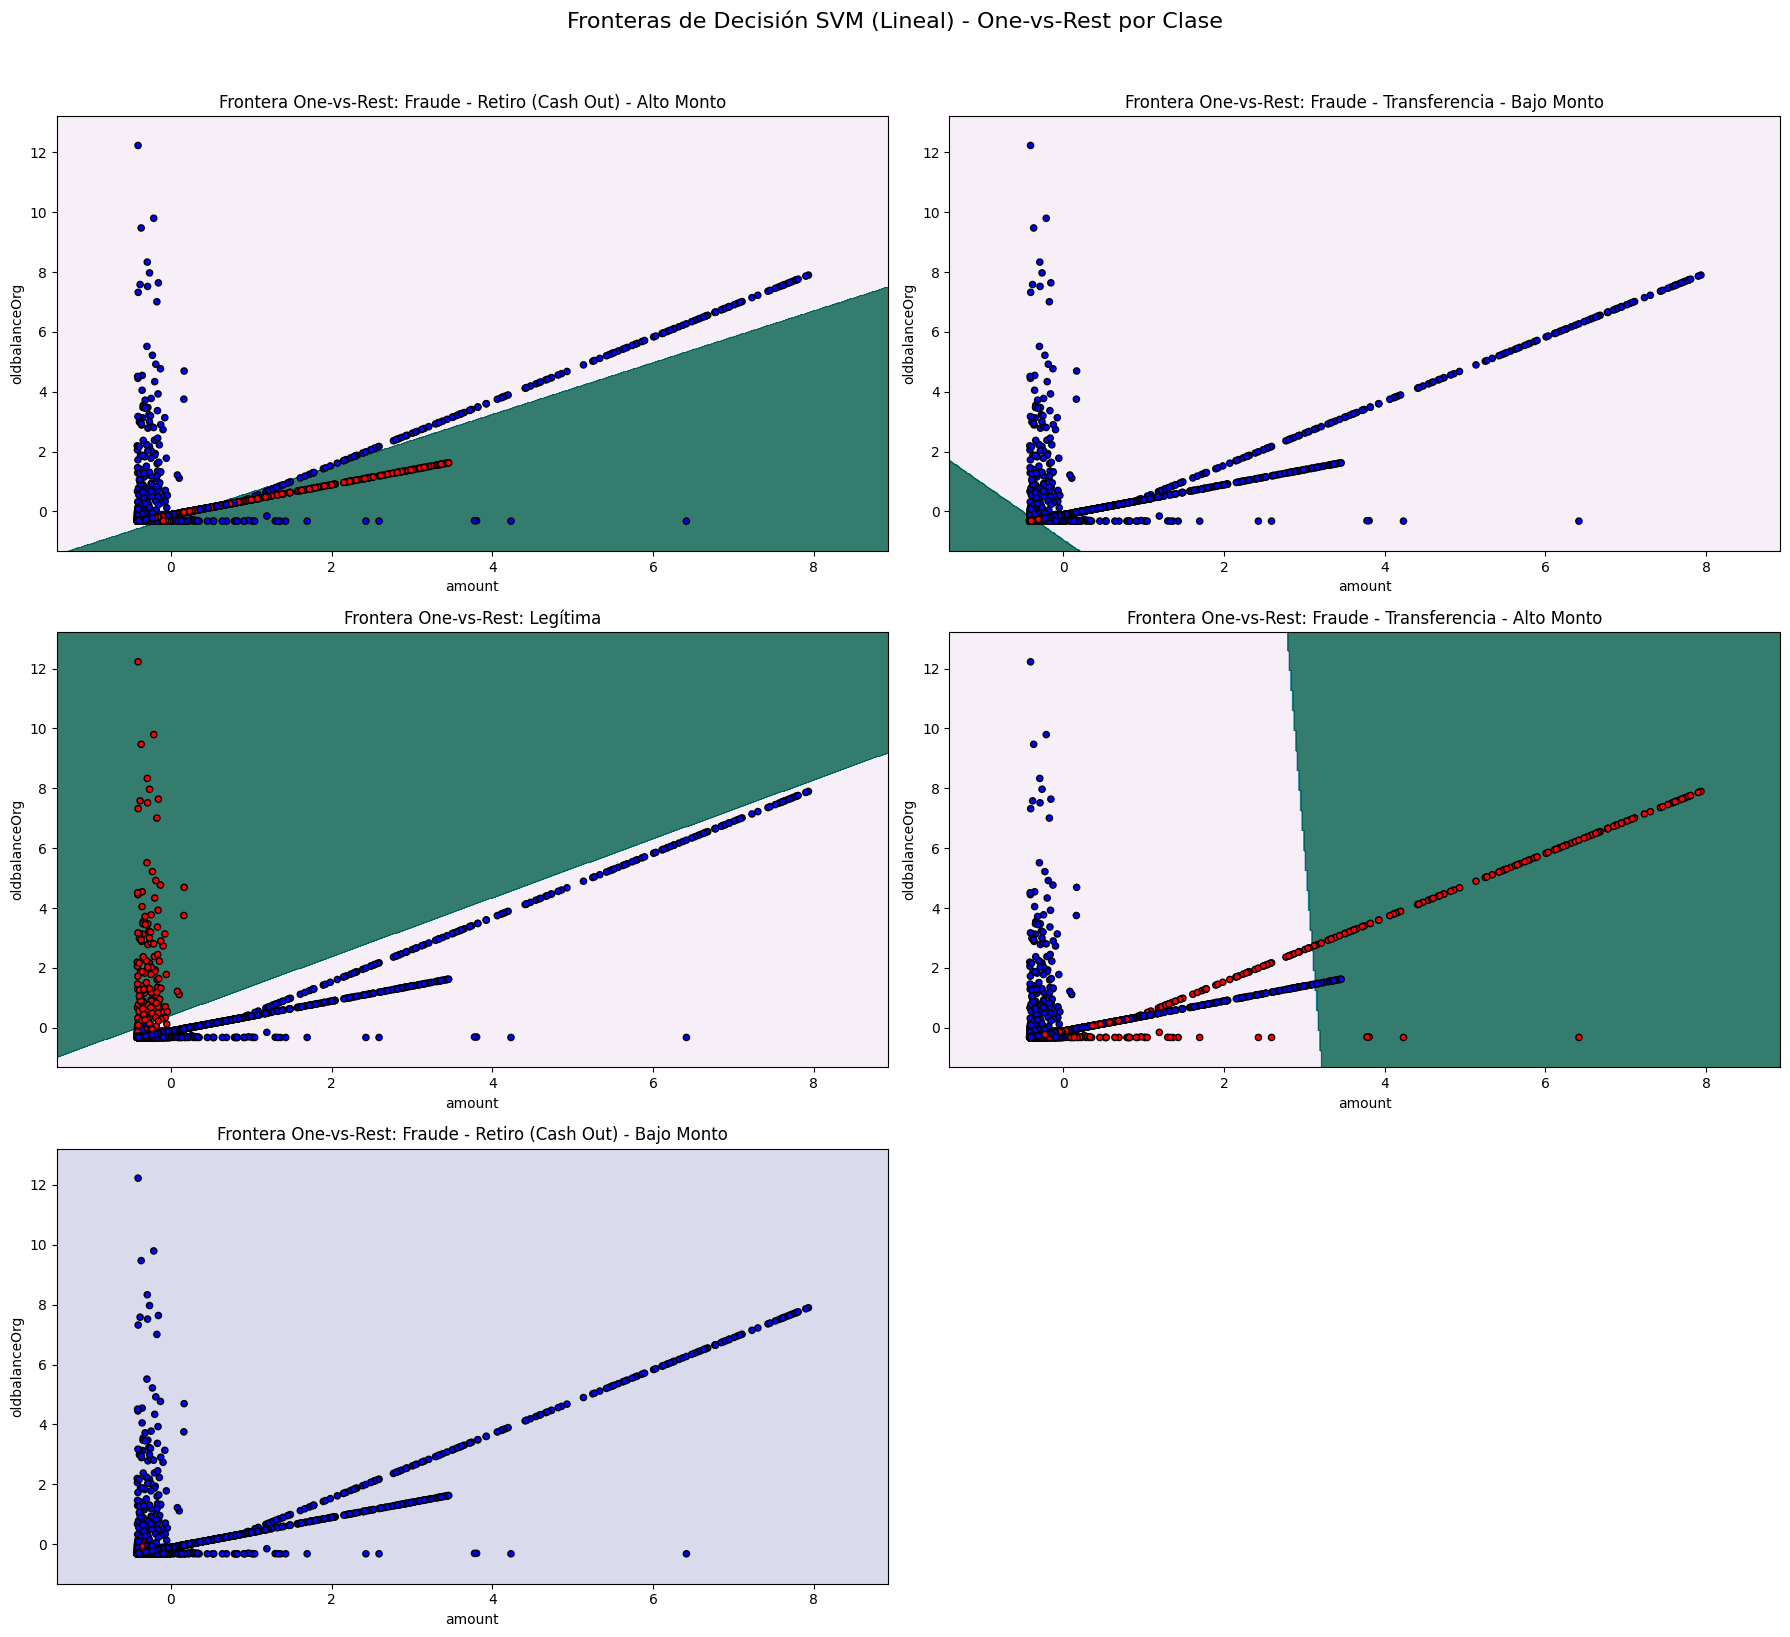

In [8]:
# Seleccionamos solo dos características para visualizar en 2D
features_vis = ["amount", "oldbalanceOrg"]
X_vis = df[features_vis]
y_vis = df["clase_objetivo"]

# Escalamiento
scaler_vis = StandardScaler()
X_vis_scaled = scaler_vis.fit_transform(X_vis)

# Lista de clases únicas
clases = y_vis.unique()

# Creamos 5 modelos One-vs-Rest, uno por clase
plt.figure(figsize=(18, 16))

for i, clase in enumerate(clases, 1):
    # Creamos etiquetas binarias: 1 si es la clase actual, 0 si es cualquier otra
    y_binaria = (y_vis == clase).astype(int)

    # Entrenamos modelo lineal SVM para esta clase
    modelo = SVC(kernel='linear')
    modelo.fit(X_vis_scaled, y_binaria)

    # Malla para graficar la frontera
    h = 0.02
    x_min, x_max = X_vis_scaled[:, 0].min() - 1, X_vis_scaled[:, 0].max() + 1
    y_min, y_max = X_vis_scaled[:, 1].min() - 1, X_vis_scaled[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = modelo.predict(grid).reshape(xx.shape)

    # Plot para la clase actual
    plt.subplot(3, 2, i)
    plt.contourf(xx, yy, Z, cmap=plt.cm.PuBuGn, alpha=0.8)

    # Colorear los puntos según si son o no de la clase actual
    colores = np.where(y_binaria == 1, 'red', 'blue')
    plt.scatter(X_vis_scaled[:, 0], X_vis_scaled[:, 1], c=colores, edgecolor='k', s=20)

    plt.title(f'Frontera One-vs-Rest: {clase}', fontsize=12)
    plt.xlabel(features_vis[0])
    plt.ylabel(features_vis[1])
    plt.tight_layout()

plt.suptitle("Fronteras de Decisión SVM (Lineal) - One-vs-Rest por Clase", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


### 📊 9. Visualización de Regiones de Decisión (2D)

Similar a la sección anterior, se visualizan las regiones de decisión, pero esta vez utilizando un clasificador `OneVsRestClassifier` con un kernel RBF, entrenado en las mismas dos características (`amount`, `oldbalanceOrg`). Se genera una malla y se predice la clase para cada punto de la malla utilizando el modelo OvR multiclase. Las regiones de decisión se muestran utilizando un mapa de colores, y los puntos de datos se colorean según su clase real para mostrar cómo caen dentro de las regiones predichas. Se añade una barra de color para mapear los colores a las clases correspondientes.

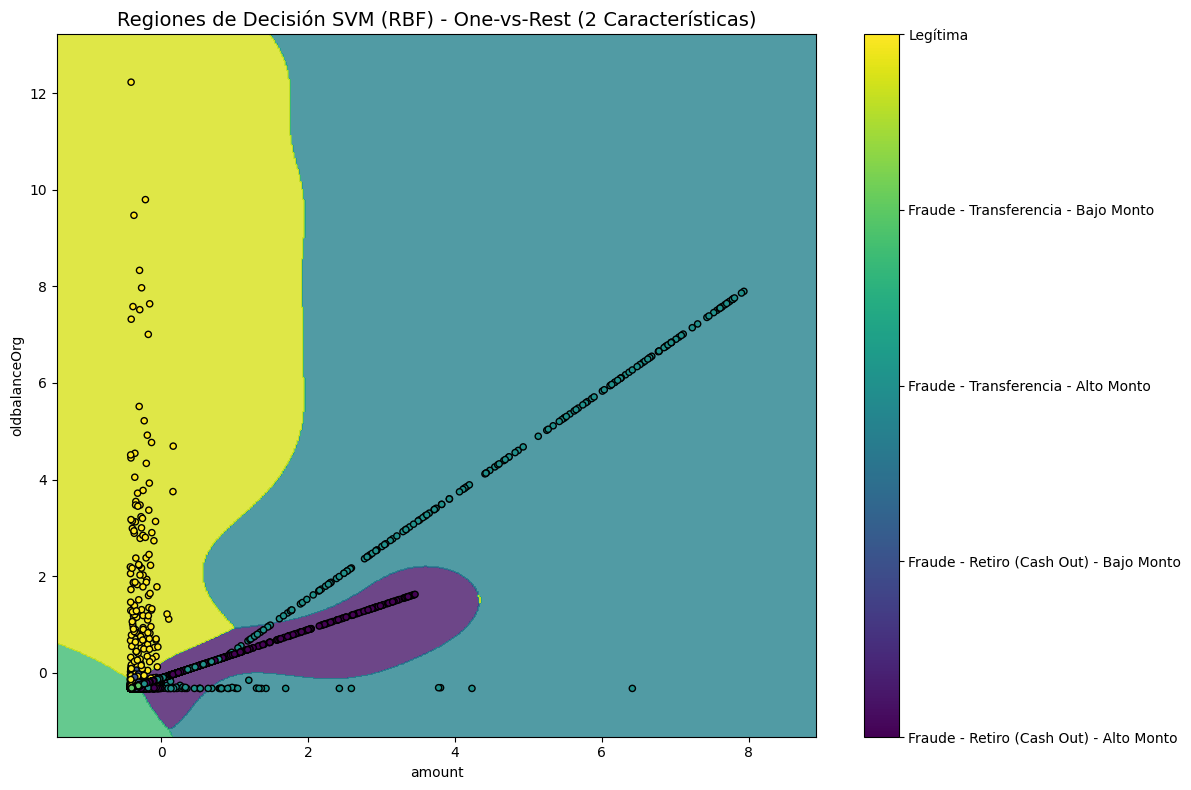

In [9]:
# Entrenar un clasificador One-vs-Rest en los datos 2D
# Usamos un kernel RBF como en los modelos principales, pero con C=1 para consistencia
modelo_ovr_2d = OneVsRestClassifier(SVC(kernel="rbf", C=1))
modelo_ovr_2d.fit(X_vis_scaled, y_vis)

# Malla para graficar las regiones de decisión
h = 0.02
x_min, x_max = X_vis_scaled[:, 0].min() - 1, X_vis_scaled[:, 0].max() + 1
y_min, y_max = X_vis_scaled[:, 1].min() - 1, X_vis_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

grid = np.c_[xx.ravel(), yy.ravel()]
Z = modelo_ovr_2d.predict(grid).reshape(xx.shape)

# Mapear las clases a valores numéricos para el contorno
clase_a_valor = {clase: i for i, clase in enumerate(np.unique(y_vis))}
Z_numeric = np.array([clase_a_valor[clase] for clase in Z.ravel()]).reshape(xx.shape)

# Plot de las regiones de decisión
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, Z_numeric, cmap=plt.cm.viridis, alpha=0.8)

# Colorear los puntos según su clase real
scatter = plt.scatter(X_vis_scaled[:, 0], X_vis_scaled[:, 1], c=[clase_a_valor[clase] for clase in y_vis],
                      edgecolor='k', s=20, cmap=plt.cm.viridis)

plt.title("Regiones de Decisión SVM (RBF) - One-vs-Rest (2 Características)", fontsize=14)
plt.xlabel(features_vis[0])
plt.ylabel(features_vis[1])
plt.colorbar(scatter, ticks=list(clase_a_valor.values())).set_ticklabels(list(clase_a_valor.keys()))
plt.tight_layout()
plt.show()

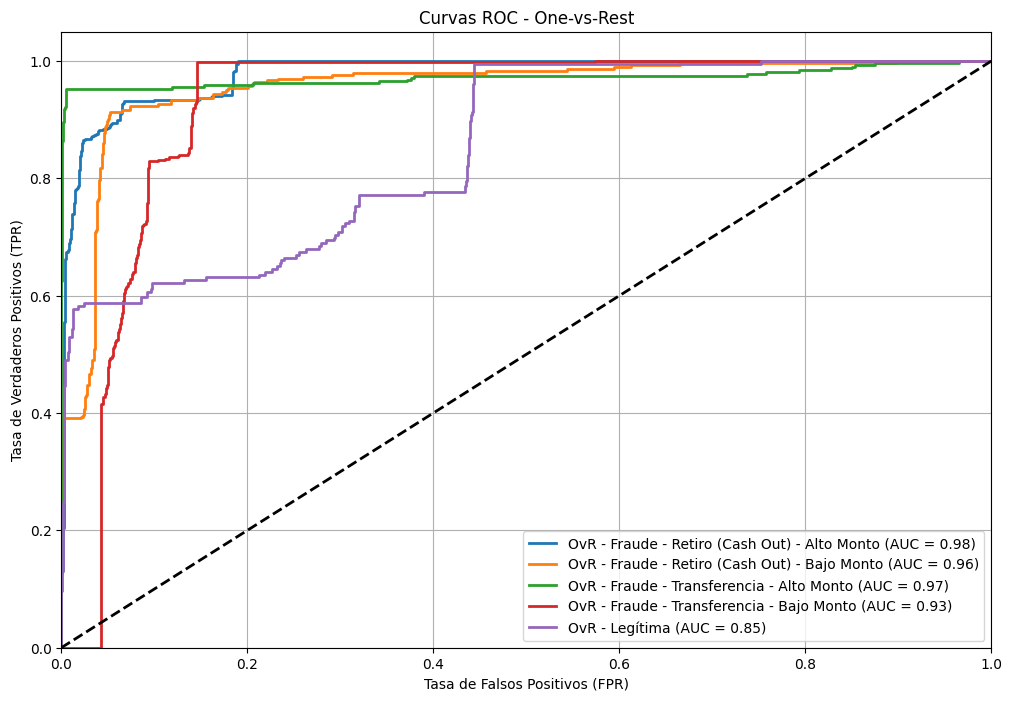

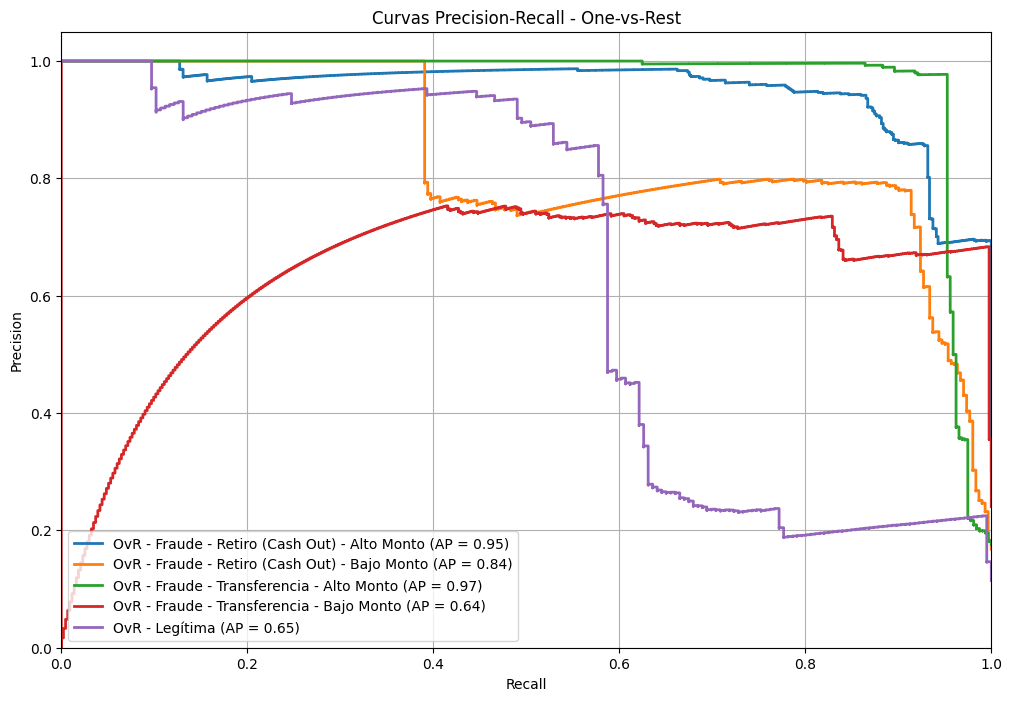

In [10]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np

# Re-train the OneVsRestClassifier with probability=True
# Assuming X_train_scaled and y_train are available from previous steps
modelo_ovr = OneVsRestClassifier(SVC(kernel="rbf", C=1, probability=True))
modelo_ovr.fit(X_train_scaled, y_train)


# Calculate the probability scores for OvR
y_score_ovr = modelo_ovr.predict_proba(X_test_scaled)

# Binarizar las etiquetas verdaderas para el cálculo por clase
classes = np.unique(y)
y_test_binarized = label_binarize(y_test, classes=classes)

# --- Curvas ROC ---
plt.figure(figsize=(12, 8))

# Curvas ROC para OvR
fpr_ovr = dict()
tpr_ovr = dict()
roc_auc_ovr = dict()
for i in range(len(classes)):
    fpr_ovr[i], tpr_ovr[i], _ = roc_curve(y_test_binarized[:, i], y_score_ovr[:, i])
    roc_auc_ovr[i] = auc(fpr_ovr[i], tpr_ovr[i])
    plt.plot(fpr_ovr[i], tpr_ovr[i], lw=2, label=f'OvR - {classes[i]} (AUC = {roc_auc_ovr[i]:.2f})')


plt.plot([0, 1], [0, 1], 'k--', lw=2) # Curva de referencia aleatoria
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curvas ROC - One-vs-Rest')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# --- Curvas Precision-Recall ---
plt.figure(figsize=(12, 8))

# Curvas Precision-Recall para OvR
precision_ovr = dict()
recall_ovr = dict()
average_precision_ovr = dict()
for i in range(len(classes)):
    precision_ovr[i], recall_ovr[i], _ = precision_recall_curve(y_test_binarized[:, i], y_score_ovr[:, i])
    average_precision_ovr[i] = average_precision_score(y_test_binarized[:, i], y_score_ovr[:, i])
    plt.step(recall_ovr[i], precision_ovr[i], where='post', lw=2, label=f'OvR - {classes[i]} (AP = {average_precision_ovr[i]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curvas Precision-Recall - One-vs-Rest')
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

# Note: If you want to plot for the OvO model as well,
# make sure that modelo_ovo was trained with probability=True
# and uncomment/adapt the code to calculate y_score_ovo and plot its curves.

In [11]:
# Seleccionar 3 índices aleatorios del conjunto de prueba
np.random.seed(42) # for reproducibility
sample_indices = np.random.choice(len(X_test_scaled), 3, replace=False)

# Obtener los datos de prueba escalados y las etiquetas reales para estos índices
X_sample = X_test_scaled[sample_indices]
y_sample_real = y_test.iloc[sample_indices]

# Realizar predicciones con el modelo One-vs-Rest
y_sample_pred = modelo_ovr.predict(X_sample)

# Mostrar los resultados
print("Resultados para 3 casos de prueba:")
for i in range(len(sample_indices)):
    print(f"\nCaso de Prueba {i+1}:")
    print(f"  Predicción del modelo: {y_sample_pred[i]}")
    print(f"  Resultado Real: {y_sample_real.iloc[i]}")

Resultados para 3 casos de prueba:

Caso de Prueba 1:
  Predicción del modelo: Fraude - Transferencia - Bajo Monto
  Resultado Real: Legítima

Caso de Prueba 2:
  Predicción del modelo: Fraude - Transferencia - Alto Monto
  Resultado Real: Fraude - Transferencia - Alto Monto

Caso de Prueba 3:
  Predicción del modelo: Fraude - Transferencia - Alto Monto
  Resultado Real: Fraude - Transferencia - Alto Monto
